# Assignment 2 — Part 3: Model Fine-Tuning (DistilBERT)

**Course:** Large Language Models for Marketing  
**Run this notebook on Google Colab with a T4 GPU:**  
Runtime → Change runtime type → T4 GPU

**Before running:** upload `Yelp Restaurant Reviews 2.csv` to the Colab file browser (left panel).

**Two configurations compared:**

| | Config A | Config B |
|---|---|---|
| Layers trained | All (full fine-tuning) | Classifier head only (frozen base) |
| Learning rate | 2e-5 | 1e-4 |
| Rationale | Standard approach | Faster, less risk of catastrophic forgetting |

In [ ]:
%pip install transformers datasets scikit-learn pandas numpy torch --quiet

In [1]:
# ── Imports ───────────────────────────────────────────────────
import random, warnings
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    TrainingArguments,
    Trainer,
)
from sklearn.metrics import accuracy_score, mean_absolute_error, classification_report
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")
if device == 'cpu':
    print("WARNING: No GPU. Go to Runtime → Change runtime type → T4 GPU.")

Device: cuda


In [2]:
# ── Load data ─────────────────────────────────────────────────
df = pd.read_csv('Yelp Restaurant Reviews 2.csv')
df.columns = ['url', 'stars', 'date', 'text']
df['stars'] = df['stars'].astype(int)
print(f"Total reviews: {len(df):,}")
print(df['stars'].value_counts().sort_index())

Total reviews: 19,896
stars
1     1217
2     1280
3     2069
4     4447
5    10883
Name: count, dtype: int64


In [3]:
# ── Stratified train / val / test split ───────────────────────
# 800 train (160/star) | 200 val (40/star) | 200 test (40/star)
TRAIN_PER_STAR = 160
VAL_PER_STAR   = 40
TEST_PER_STAR  = 40

def stratified_sample(dataframe, per_star, seed=42):
    return pd.concat([
        dataframe[dataframe['stars'] == star].sample(per_star, random_state=seed)
        for star in [1, 2, 3, 4, 5]
    ]).reset_index(drop=True)

train_df   = stratified_sample(df, TRAIN_PER_STAR)
remaining  = df.drop(index=train_df.index).reset_index(drop=True)
val_df     = stratified_sample(remaining, VAL_PER_STAR)
remaining2 = remaining.drop(index=val_df.index).reset_index(drop=True)
test_df    = stratified_sample(remaining2, TEST_PER_STAR)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("Train distribution:", train_df['stars'].value_counts().sort_index().to_dict())

Train: 800 | Val: 200 | Test: 200
Train distribution: {1: 160, 2: 160, 3: 160, 4: 160, 5: 160}


In [4]:
# ── Tokenise & build PyTorch datasets ────────────────────────
MODEL_NAME = 'distilbert-base-uncased'
tokenizer  = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

class YelpDataset(Dataset):
    def __init__(self, dataframe):
        texts  = dataframe['text'].tolist()
        labels = (dataframe['stars'] - 1).tolist()   # 0-indexed: stars 1-5 → 0-4
        enc    = tokenizer(texts, padding=True, truncation=True,
                           max_length=128, return_tensors='pt')
        self.input_ids      = enc['input_ids']
        self.attention_mask = enc['attention_mask']
        self.labels         = torch.tensor(labels, dtype=torch.long)

    def __len__(self):  return len(self.labels)

    def __getitem__(self, idx):
        return {'input_ids':      self.input_ids[idx],
                'attention_mask': self.attention_mask[idx],
                'labels':         self.labels[idx]}

train_dataset = YelpDataset(train_df)
val_dataset   = YelpDataset(val_df)
test_dataset  = YelpDataset(test_df)
print("Datasets ready.")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Datasets ready.


In [5]:
# ── Evaluation metrics ────────────────────────────────────────
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': round(accuracy_score(labels, preds), 4),
        'mae':      round(mean_absolute_error(labels, preds), 4),
    }

In [6]:
# ── CONFIG A: Full fine-tuning (all layers trainable) ─────────
print('=' * 60)
print('CONFIG A — Full fine-tuning')
print('=' * 60)

model_A = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)
n_trainable_A = sum(p.numel() for p in model_A.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_trainable_A:,}")

trainer_A = Trainer(
    model           = model_A,
    args            = TrainingArguments(
        output_dir                  = './results_A',
        num_train_epochs            = 3,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 32,
        learning_rate               = 2e-5,
        weight_decay                = 0.01,
        eval_strategy               = 'epoch',
        save_strategy               = 'epoch',
        load_best_model_at_end      = True,
        metric_for_best_model       = 'accuracy',
        logging_steps               = 50,
        seed                        = 42,
        report_to                   = 'none',
    ),
    train_dataset   = train_dataset,
    eval_dataset    = val_dataset,
    compute_metrics = compute_metrics,
)
trainer_A.train()
print('\nConfig A complete.')

CONFIG A — Full fine-tuning


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].



Config A complete.


In [7]:
# ── CONFIG B: Frozen base — only classifier head trained ──────
print('=' * 60)
print('CONFIG B — Frozen base layers (head only)')
print('=' * 60)

model_B = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)

# Freeze all transformer layers; only the classification head stays trainable
for param in model_B.distilbert.parameters():
    param.requires_grad = False

n_trainable_B = sum(p.numel() for p in model_B.parameters() if p.requires_grad)
n_total_B     = sum(p.numel() for p in model_B.parameters())
print(f"Trainable: {n_trainable_B:,} / {n_total_B:,} ({n_trainable_B/n_total_B:.1%})")

trainer_B = Trainer(
    model           = model_B,
    args            = TrainingArguments(
        output_dir                  = './results_B',
        num_train_epochs            = 3,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 32,
        learning_rate               = 1e-4,   # higher LR since only head is trained
        weight_decay                = 0.01,
        eval_strategy               = 'epoch',
        save_strategy               = 'epoch',
        load_best_model_at_end      = True,
        metric_for_best_model       = 'accuracy',
        logging_steps               = 50,
        seed                        = 42,
        report_to                   = 'none',
    ),
    train_dataset   = train_dataset,
    eval_dataset    = val_dataset,
    compute_metrics = compute_metrics,
)
trainer_B.train()
print('\nConfig B complete.')

CONFIG B — Frozen base layers (head only)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable: 594,437 / 66,957,317 (0.9%)


Epoch,Training Loss,Validation Loss,Accuracy,Mae
1,1.594771,1.552910,0.385000,0.840000
2,1.545159,1.516156,0.410000,0.875000
3,1.512875,1.504645,0.445000,0.760000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].



Config B complete.


In [8]:
# ── Evaluate both on held-out TEST set ───────────────────────
print('=' * 60)
print('TEST SET RESULTS')
print('=' * 60)

res_A   = trainer_A.predict(test_dataset)
res_B   = trainer_B.predict(test_dataset)
preds_A = np.argmax(res_A.predictions, axis=-1)
preds_B = np.argmax(res_B.predictions, axis=-1)
true_y  = res_A.label_ids

summary = pd.DataFrame({
    'Config':            ['A — Full fine-tuning', 'B — Head only'],
    'LR':                ['2e-5', '1e-4'],
    'Trainable params':  [f"{n_trainable_A:,}", f"{n_trainable_B:,}"],
    'Accuracy':          [round(accuracy_score(true_y, preds_A), 4),
                          round(accuracy_score(true_y, preds_B), 4)],
    'MAE (0–4 scale)':   [round(mean_absolute_error(true_y, preds_A), 4),
                          round(mean_absolute_error(true_y, preds_B), 4)],
})
print(summary.to_string(index=False))

TEST SET RESULTS


              Config   LR Trainable params  Accuracy  MAE (0–4 scale)
A — Full fine-tuning 2e-5       66,957,317     0.475            0.735
       B — Head only 1e-4          594,437     0.415            0.860


In [9]:
# ── Per-class report for the best config ─────────────────────
best_preds = preds_A if summary['Accuracy'][0] >= summary['Accuracy'][1] else preds_B
best_name  = 'Config A' if summary['Accuracy'][0] >= summary['Accuracy'][1] else 'Config B'
print(f"Detailed classification report — {best_name}:")
print(classification_report(true_y, best_preds, target_names=['1★','2★','3★','4★','5★']))

Detailed classification report — Config A:
              precision    recall  f1-score   support

          1★       0.57      0.42      0.49        40
          2★       0.38      0.45      0.41        40
          3★       0.39      0.35      0.37        40
          4★       0.43      0.30      0.35        40
          5★       0.58      0.85      0.69        40

    accuracy                           0.47       200
   macro avg       0.47      0.47      0.46       200
weighted avg       0.47      0.47      0.46       200



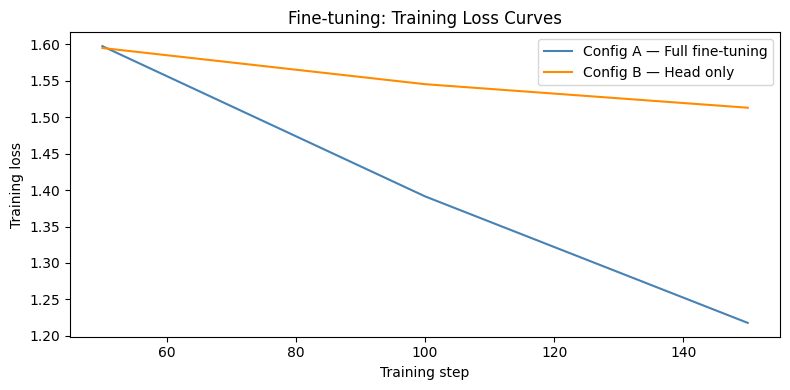

Done. Download part3_loss_curves.png from the Colab file browser.


In [10]:
# ── Training loss curves ──────────────────────────────────────
def get_loss(trainer):
    steps, losses = [], []
    for e in trainer.state.log_history:
        if 'loss' in e and 'eval_loss' not in e:
            steps.append(e['step'])
            losses.append(e['loss'])
    return steps, losses

sA, lA = get_loss(trainer_A)
sB, lB = get_loss(trainer_B)

plt.figure(figsize=(8, 4))
plt.plot(sA, lA, label='Config A — Full fine-tuning', color='steelblue')
plt.plot(sB, lB, label='Config B — Head only',        color='darkorange')
plt.xlabel('Training step')
plt.ylabel('Training loss')
plt.title('Fine-tuning: Training Loss Curves')
plt.legend()
plt.tight_layout()
plt.savefig('part3_loss_curves.png', dpi=150)
plt.show()
print("Done. Download part3_loss_curves.png from the Colab file browser.")